To create a CNN model which should be trained on 2 classes i.e cats and dogs

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
 ## Importing all the libraries
import matplotlib.pyplot as plt
import seaborn as sns

import keras
from keras.models import Sequential
from keras.layers import Dense, Conv2D , MaxPool2D , Flatten , Dropout
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from keras.optimizers import Adam

from sklearn.metrics import classification_report,confusion_matrix

import tensorflow as tf

import cv2
import os

import numpy as np

In [ ]:
# execute this only once... if you run again, skip this part
import zipfile
with zipfile.ZipFile("/content/drive/MyDrive/11 july 2026 WEM AI HYD/5_train.zip", 'r') as zip_ref:        # get the path for train.zip using copypath. paste the link within the quotation
     # creates new folder 'cats_dogs_images' and saves all images present in train.zip
    zip_ref.extractall("/content/extracted_images")  # create a new folder, rename it and get the path of it using copypath.. paste the link here



In [3]:
from zipfile import ZipFile
zip_ref = ZipFile("/content/drive/MyDrive/11 july 2026 WEM AI HYD/5_train.zip", 'r')
zip_ref.extractall("/content/extracted_images")
zip_ref.close()

In [4]:
files_list = os.listdir("/content/extracted_images/train")

# Count the number of files
num_files = len(files_list)
print(num_files)

25000


In [ ]:
print(files_list)

['cat.12198.jpg', 'cat.2226.jpg', 'cat.4824.jpg', 'cat.291.jpg', 'cat.10055.jpg', 'dog.10844.jpg', 'cat.2174.jpg', 'cat.1789.jpg', 'cat.2035.jpg', 'dog.12456.jpg', 'cat.9304.jpg', 'cat.10900.jpg', 'cat.8389.jpg', 'dog.4715.jpg', 'cat.5651.jpg', 'cat.12105.jpg', 'dog.6862.jpg', 'dog.9163.jpg', 'cat.11512.jpg', 'cat.3448.jpg', 'cat.4862.jpg', 'cat.10839.jpg', 'dog.2487.jpg', 'dog.8754.jpg', 'dog.11553.jpg', 'cat.6000.jpg', 'cat.8658.jpg', 'dog.2044.jpg', 'cat.2328.jpg', 'cat.7160.jpg', 'cat.8941.jpg', 'cat.7505.jpg', 'cat.9326.jpg', 'cat.5951.jpg', 'dog.12318.jpg', 'dog.2665.jpg', 'dog.3756.jpg', 'dog.8932.jpg', 'cat.2871.jpg', 'cat.12170.jpg', 'dog.4692.jpg', 'cat.3884.jpg', 'cat.7296.jpg', 'cat.7434.jpg', 'dog.3530.jpg', 'cat.7823.jpg', 'cat.1410.jpg', 'dog.3871.jpg', 'dog.11036.jpg', 'dog.521.jpg', 'dog.5341.jpg', 'cat.1963.jpg', 'cat.3219.jpg', 'dog.1860.jpg', 'dog.8570.jpg', 'cat.4398.jpg', 'cat.9323.jpg', 'dog.1525.jpg', 'dog.5443.jpg', 'dog.4637.jpg', 'cat.12259.jpg', 'cat.5262.jp

In [9]:
32*5

160

In [5]:
cat = 0
dog = 0
for word in files_list:
  if "cat" in word.lower():
    cat = cat + 1
  elif "dog" in word.lower():
    dog = dog + 1

In [6]:
print(cat)
print(dog)

12500
12500


In [10]:
import os, shutil, pathlib

original_dir = pathlib.Path(r"/content/extracted_images/train") # get the path of train folder in cats_dogs_images using copypath and paste the link here
new_base_dir = pathlib.Path(r"/content/my_images") # create a new folder, rename it and get the path using copypath and paste the link here.


# define a function to create subsets for train, test and validation
def make_subset(subset_name, start_index, end_index):
    for category in ("cat", "dog"):
        dir = new_base_dir / subset_name / category
        os.makedirs(dir)
        fnames = [f"{category}.{i}.jpg" for i in range(start_index, end_index)]
        for fname in fnames:
            shutil.copyfile(src=original_dir / fname,
                            dst=dir / fname)

# calling the function thrice to create 3 subsets.
make_subset("train", start_index=0, end_index=1000)
make_subset("validation", start_index=1000, end_index=1500)
make_subset("test", start_index=1500, end_index=2500)

In [14]:
catlist = os.listdir("/content/my_images/train/cat")
print(catlist)

['cat.862.jpg', 'cat.308.jpg', 'cat.622.jpg', 'cat.606.jpg', 'cat.267.jpg', 'cat.204.jpg', 'cat.218.jpg', 'cat.297.jpg', 'cat.345.jpg', 'cat.288.jpg', 'cat.620.jpg', 'cat.875.jpg', 'cat.923.jpg', 'cat.461.jpg', 'cat.254.jpg', 'cat.402.jpg', 'cat.375.jpg', 'cat.325.jpg', 'cat.357.jpg', 'cat.93.jpg', 'cat.634.jpg', 'cat.222.jpg', 'cat.278.jpg', 'cat.53.jpg', 'cat.569.jpg', 'cat.813.jpg', 'cat.939.jpg', 'cat.342.jpg', 'cat.982.jpg', 'cat.62.jpg', 'cat.777.jpg', 'cat.877.jpg', 'cat.465.jpg', 'cat.717.jpg', 'cat.437.jpg', 'cat.971.jpg', 'cat.57.jpg', 'cat.780.jpg', 'cat.882.jpg', 'cat.906.jpg', 'cat.863.jpg', 'cat.399.jpg', 'cat.300.jpg', 'cat.485.jpg', 'cat.52.jpg', 'cat.269.jpg', 'cat.848.jpg', 'cat.417.jpg', 'cat.712.jpg', 'cat.208.jpg', 'cat.481.jpg', 'cat.843.jpg', 'cat.499.jpg', 'cat.758.jpg', 'cat.746.jpg', 'cat.450.jpg', 'cat.139.jpg', 'cat.892.jpg', 'cat.25.jpg', 'cat.48.jpg', 'cat.907.jpg', 'cat.774.jpg', 'cat.711.jpg', 'cat.130.jpg', 'cat.96.jpg', 'cat.548.jpg', 'cat.692.jpg', 'c

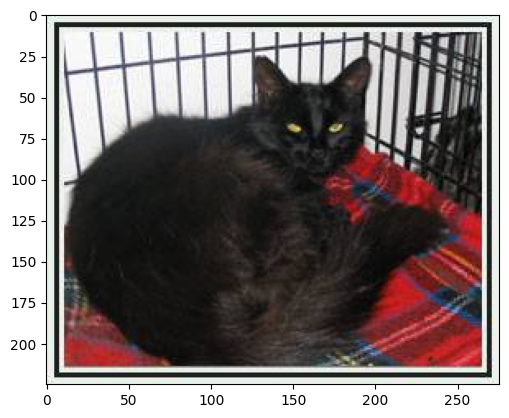

In [37]:
pic = plt.imread(f"/content/my_images/train/cat/{catlist[5]}")
plt.imshow(pic)

In [38]:
pic.shape

(225, 276, 3)

In [24]:
mango_price = 50
orange_price = 20
print("price of mango is 50 and that of orange is 20")
print(f"price of mango is {mango_price} and that of orange is {orange_price}")
print("price of mango is {} and that of orange is {}".format(mango_price,orange_price))
print("price of mango is",orange_price,"and that of orange is",orange_price)

price of mango is 50 and that of orange is 20
price of mango is 50 and that of orange is 20
price of mango is 50 and that of orange is 20
price of mango is 20 and that of orange is 20


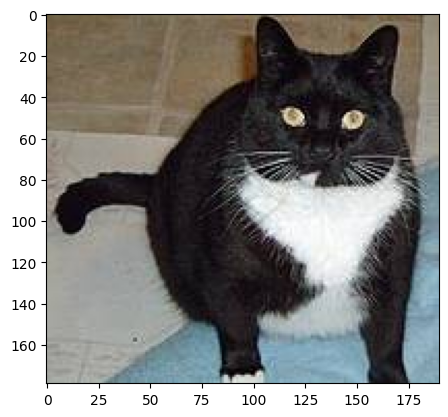

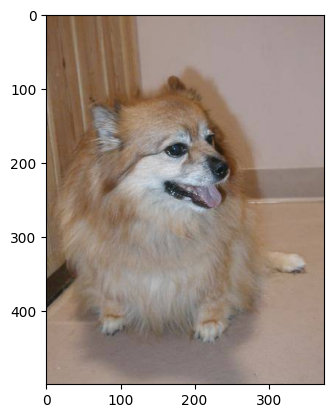

In [21]:
a = plt.imread("/content/my_images/train/dog/dog.967.jpg")
plt.imshow(a)

In [ ]:
lst = [5,10,'banana',18,12]
for i in lst:
  try:
    print(i/2)
  except Exception as e:
    print(e)




2.5
5.0
unsupported operand type(s) for /: 'str' and 'int'
9.0
6.0


In [39]:
import tensorflow as tf
from tensorflow.keras import layers, models

TRAIN_DIR = "/content/my_images/train"
VAL_DIR   = "/content/my_images/validation"
TEST_DIR  = "/content/my_images/test"

IMG_SIZE   = (224, 224)
BATCH_SIZE = 32
EPOCHS     = 20

train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    labels="inferred",
    label_mode="binary",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True,

)

val_ds = tf.keras.utils.image_dataset_from_directory(
    VAL_DIR,
    labels="inferred",
    label_mode="binary",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False,
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    labels="inferred",
    label_mode="binary",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False,
)

Found 2000 files belonging to 2 classes.
Found 1000 files belonging to 2 classes.
Found 2000 files belonging to 2 classes.


In [40]:
class_names = train_ds.class_names
print("Classes:", class_names)

Classes: ['cat', 'dog']


In [41]:
data_augmentation = models.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
], name="augmentation")



In [42]:
model = models.Sequential([
    layers.Input(shape=IMG_SIZE + (3,)),
    data_augmentation,
    layers.Rescaling(1.0 / 255),          # normalise 0-255 -> 0-1

    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.Conv2D(64, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.Conv2D(128, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.Conv2D(128, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.Flatten(),
    layers.Dropout(0.5),
    layers.Dense(128, activation="relu"),
    layers.Dense(1, activation="sigmoid"),   # binary output
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy"],
)

model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_3 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_12          │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_13          │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_14          │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_14 (MaxPooling2D) │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 28, 28, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_15          │ (None, 28, 28, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_15 (MaxPooling2D) │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,453,761 (13.18 MB)

 Trainable params: 3,453,057 (13.17 MB)

 Non-trainable params: 704 (2.75 KB)

In [43]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
)

Epoch 1/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 280s 4s/step - accuracy: 0.5420 - loss: 1.1309 - val_accuracy: 0.5460 - val_loss: 0.8444
Epoch 2/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 277s 4s/step - accuracy: 0.6135 - loss: 0.6677 - val_accuracy: 0.5220 - val_loss: 0.8899
Epoch 3/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 278s 4s/step - accuracy: 0.6505 - loss: 0.6370 - val_accuracy: 0.5990 - val_loss: 0.7500
Epoch 4/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 303s 4s/step - accuracy: 0.6500 - loss: 0.6231 - val_accuracy: 0.5340 - val_loss: 0.9743
Epoch 5/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 259s 4s/step - accuracy: 0.7145 - loss: 0.5620 - val_accuracy: 0.5300 - val_loss: 1.4628
Epoch 6/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 262s 4s/step - accuracy: 0.7350 - loss: 0.5447 - val_accuracy: 0.5570 - val_loss: 1.3145
Epoch 7/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 275s 4s/step - accuracy: 0.7410 - loss: 0.5251 - val_accuracy: 0.6670 - val_loss: 0.6871
Epoch 8/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 266s 4s/step - accuracy: 0.7420 - loss: 0.5115 - val_accuracy: 0.6790 - v

KeyboardInterrupt: 

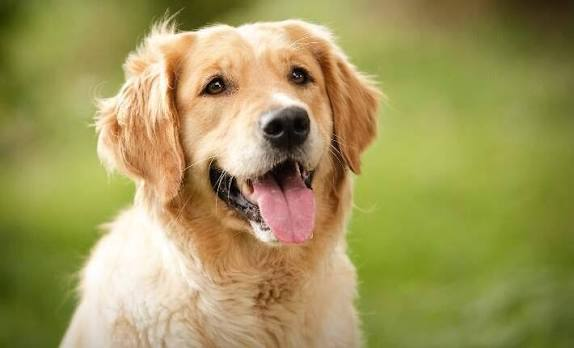

In [79]:
import cv2
from google.colab.patches import cv2_imshow
test = cv2.imread("/content/dog1.jfif")
cv2_imshow(test)

In [80]:
mypic  =(cv2.resize((test.astype('float32')/255), (224,224)))
mypic.shape

(224, 224, 3)

In [81]:
mybatch = mypic.reshape(1,224,224,3)

In [82]:
pred = model.predict(mybatch)[0][0]
pred

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step


np.float32(0.23393592)

In [72]:
if model.predict(mybatch)[0][0] <= 0.5:
  print('cat')
else:
  print("dog")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
cat


In [ ]:
## This step helps in converting all the images present in folder to same shape.
import cv2
import numpy as np
labels = ['cat', 'dog']
img_size = 224
def get_data(data_dir):
    data = []
    for label in labels:
        path = os.path.join(data_dir, label) # path to cat folder inside train folder
        class_num = labels.index(label) # 0
        for img in os.listdir(path):
            try:
                img_arr = cv2.imread(os.path.join(path, img)) #convert BGR to RGB format
                resized_arr = cv2.resize(img_arr, (224, 224)) # Reshaping images to preferred size
                data.append([resized_arr, class_num])
            except Exception as e:
                print(e)
    return np.array(data,dtype="object")

In [ ]:
a = [[1,6],[2,4],[6,2]]
type(a)

list

In [ ]:
b = np.array(a)
print(b)
print(b.ndim)

[[1 6]
 [2 4]
 [6 2]]
2


In [ ]:
32*32*3

3072

In [ ]:
pic1 = np.random.rand(3072).reshape(32,32,3)
pic2 = np.random.rand(3072).reshape(32,32,3)
pic3 = np.random.rand(3072).reshape(32,32,3)


In [ ]:
x = [[pic1,6],[pic2,4],[pic3,2]]

In [ ]:
y = np.array(x,dtype='object')

In [ ]:
train = get_data(r'/content/my_images/train')
val = get_data(r'/content/my_images/validation')



In [ ]:
print(type(train))
print(train.shape)

<class 'numpy.ndarray'>
(2000, 2)


In [ ]:
train[1500][0]

In [ ]:
train[1500][1]

In [ ]:
a = 1
b = 2
c = 3
# [[a,123],[b,213],3[c,1]]
myarr = np.array([[1,123],[2,213],[3,31]])
print(myarr)
print(myarr.shape)

## The numpy array is able to convert nested list into 2d np array because the element of nested list is of same data type

In [ ]:
image1 = np.array([[2,3],[4,5]])
image2 = np.array([[5,3],[7,4]])
image3 = np.array([[3,4],[8,8]])

np.array([[image1,0],[image2,0],[image3,0]])
## The numpy array is unable to convert nested list into 2d np array because the element of nested list is of different data type

In [ ]:
## Setting up every element inside the numpy array as Object to convert nested list into 2d np array
np.array([[image1,0],[image2,0],[image3,0]],dtype=object)

In [ ]:
np.array([[image1,0],[image2,0],[image3,0]],dtype=object).shape

In [ ]:
print(len(train))
print(len(val))
print(train.shape)
print(val.shape)

In [ ]:
type(0)

In [ ]:
print(type(train[1999][0]))
print(type(train[1999][1]))

In [ ]:
import sys
a = 23
b = 23.45
print(sys.getsizeof(a))
print(sys.getsizeof(b))

28
24


In [ ]:
np.zeros((3,3))

array([[0., 0., 0.],
       [0., 0., 0.],
       [0., 0., 0.]])

In [ ]:
x_train = []
y_train = []
x_val = []
y_val = []

for feature, label in train:
  x_train.append(np.array(feature))
  y_train.append(int(label))

for feature, label in val:
  x_val.append(np.array(feature))
  y_val.append(int(label))

# Normalize the data
x_train = np.array(x_train).astype('float32') / 255
x_val = np.array(x_val).astype('float32') / 255

y_train = np.array(y_train)
y_val = np.array(y_val)


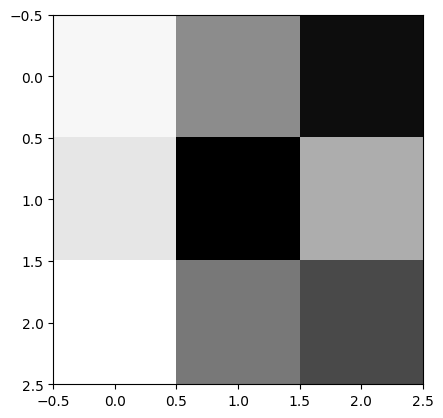

In [ ]:
from google.colab.patches import cv2_imshow
channel1 = np.array([[45,134,212],[67,221,113],[34,147,178]])
plt.imshow(channel1,cmap="Grays")

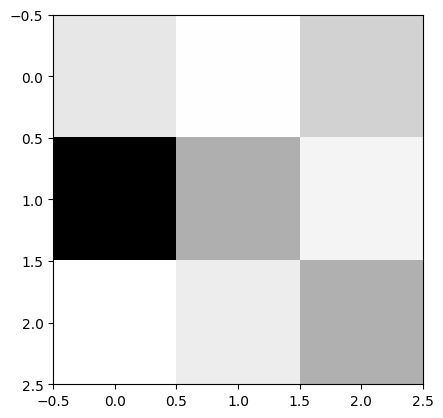

In [ ]:
channel2 = np.array([[54,14,79],[252,113,34],[12,45,112]])
plt.imshow(channel2,cmap='Grays')

In [ ]:
channel3 = np.array([[56,24,116],[11,26,86],[46,166,233]])
# plt.imshow(channel3,cmap='Grays')
print(channel3.shape)

(3, 3)


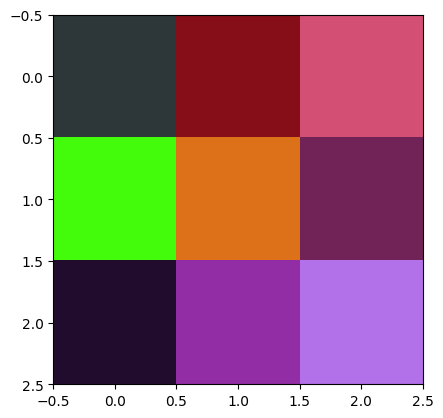

In [ ]:
pic = np.stack([channel1,channel2,channel3],axis=2)
plt.imshow(pic)

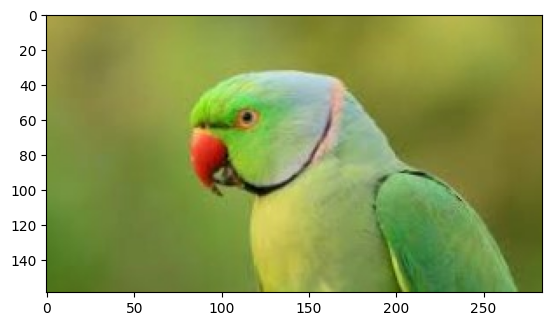

In [ ]:
pic = plt.imread("/content/parrot.jpg")
plt.imshow(pic)

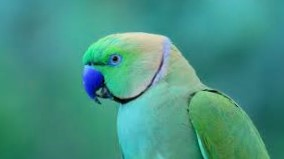

In [ ]:
cv2_imshow(pic)

In [ ]:
from keras.datasets import mnist
(X_train,y_train),(X_test,y_test)=mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


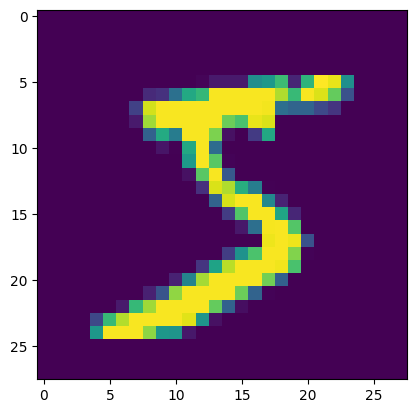

In [ ]:
pic = X_train[0]
plt.imshow(pic,cmap='viridis')

In [ ]:
cv2_imshow(pic)

In [ ]:
## Generating data or images during runtime for training purpose.DO not do it for testing
datagen = ImageDataGenerator(
        featurewise_center=True,  # set input mean to 0 over the dataset
        samplewise_center=False,  # set each sample mean to 0
        featurewise_std_normalization=False,  # divide inputs by std of the dataset
        samplewise_std_normalization=False,  # divide each input by its std
        zca_whitening=False,  # apply ZCA whitening
        rotation_range = 30,  # randomly rotate images in the range (degrees, 0 to 180)
        zoom_range = 0.2, # Randomly zoom image
        width_shift_range=0.1,  # randomly shift images horizontally (fraction of total width)
        height_shift_range=0.1,  # randomly shift images vertically (fraction of total height)
        horizontal_flip = True,  # randomly flip images
        vertical_flip=False)  # randomly flip images


datagen.fit(x_train)


In [ ]:
type(datagen)

In [ ]:
x_train.shape

(2000, 224, 224, 3)

In [ ]:
model = Sequential()
model.add(Conv2D(32,3,padding="same", activation="relu", input_shape=(224,224,3)))
model.add(MaxPool2D())

model.add(Conv2D(32, 3, padding="same", activation="relu"))
model.add(MaxPool2D())

model.add(Conv2D(64, 3, padding="same", activation="relu"))
model.add(MaxPool2D())
model.add(Dropout(0.4))

model.add(Flatten())
model.add(Dense(128,activation="relu"))
model.add(Dense(1, activation="sigmoid"))

model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 28, 28, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 50176)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     6,422,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,451,425 (24.61 MB)

 Trainable params: 6,451,425 (24.61 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
#tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True)
opt = Adam(learning_rate=0.000001)
model.compile(optimizer = opt , loss = "binary_crossentropy" , metrics = ['accuracy'])

In [ ]:
type(x_train)

In [ ]:
type(y_train)

In [ ]:
#history = model.fit(x_train,y_train,epochs = 10 , validation_data = (x_val, y_val))


from keras.callbacks import ModelCheckpoint

# train the model
checkpointer = ModelCheckpoint(filepath='model.weights.best.keras', verbose=1, save_best_only=True)

hist = model.fit(datagen.flow(x_train, y_train, batch_size=32), epochs=100,
          validation_data=(x_val, y_val), callbacks=[checkpointer],
          verbose=2, shuffle=True)

Epoch 1/100

Epoch 1: val_loss improved from None to 0.69143, saving model to model.weights.best.keras

Epoch 1: finished saving model to model.weights.best.keras
63/63 - 182s - 3s/step - accuracy: 0.5165 - loss: 0.6931 - val_accuracy: 0.5050 - val_loss: 0.6914
Epoch 2/100

Epoch 2: val_loss improved from 0.69143 to 0.69071, saving model to model.weights.best.keras

Epoch 2: finished saving model to model.weights.best.keras
63/63 - 180s - 3s/step - accuracy: 0.5240 - loss: 0.6915 - val_accuracy: 0.5210 - val_loss: 0.6907
Epoch 3/100

Epoch 3: val_loss improved from 0.69071 to 0.68992, saving model to model.weights.best.keras

Epoch 3: finished saving model to model.weights.best.keras
63/63 - 185s - 3s/step - accuracy: 0.5260 - loss: 0.6908 - val_accuracy: 0.5290 - val_loss: 0.6899
Epoch 4/100

Epoch 4: val_loss improved from 0.68992 to 0.68923, saving model to model.weights.best.keras

Epoch 4: finished saving model to model.weights.best.keras
63/63 - 179s - 3s/step - accuracy: 0.5360 

KeyboardInterrupt: 

In [ ]:
acc = hist.history['accuracy']
val_acc = hist.history['val_accuracy']
loss = hist.history['loss']
val_loss = hist.history['val_loss']

epochs_range = range(100)

plt.figure(figsize=(15, 15))
plt.subplot(2, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(2, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.show()

In [ ]:
## Task
fine tune the configuration
train the model on more than 100
take a random picture of a dog then preprocess it accordingly and send it to machine for prediction and check your result


In [1]:
import json

flare = {"classType": "C4.1", "activeRegionNum": 14503, "note": None}

as_text = json.dumps(flare)
print(as_text)
print(type(as_text))

{"classType": "C4.1", "activeRegionNum": 14503, "note": null}
<class 'str'>


In [2]:
as_text

'{"classType": "C4.1", "activeRegionNum": 14503, "note": null}'

In [3]:
str(flare)

"{'classType': 'C4.1', 'activeRegionNum': 14503, 'note': None}"